# <center>**Chapter 10 - MLP Multiclass Classification**<center>

Notebook dùng bộ dữ liệu Iris để xây dựng và đánh giá mô hình phân loại 3 loài hoa.

Các bước: khám phá dữ liệu, mã hoá nhãn, xây dựng MLP, huấn luyện và đánh giá mô hình.

## **0. Thư viện và thiết lập môi trường**

Nạp các thư viện dùng để xử lý dữ liệu, huấn luyện mô hình và đánh giá kết quả.

In [3]:
import copy
import random

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import tqdm
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

# Giúp kết quả có thể tái lập.
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.0+cpu


---
## **1. Mô tả bài toán**

- Đầu vào: 4 số đo đài hoa và cánh hoa.
- Đầu ra: một trong ba loài `Iris-setosa`, `Iris-versicolor`, `Iris-virginica`.
- Đây là bài toán phân loại đa lớp; nhãn được mã hoá one-hot và mô hình dùng cross-entropy.

---
## **2. Đọc dữ liệu**

Đọc CSV bằng pandas, dùng `iloc` để tách 4 cột đặc trưng `X` và cột nhãn `y`.

> File `iris.csv` có hàng tiêu đề nên dùng `header=0`.

In [4]:
data = pd.read_csv("data/iris.csv", header=0)

X = data.iloc[:, 0:4]
# OneHotEncoder cần y ở dạng DataFrame 2D.
y = data.iloc[:, 4:]

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
data.head()

Kích thước X: (150, 4)
Kích thước y: (150, 1)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


---
## **3. Khám phá dữ liệu (EDA)**

Kiểm tra dữ liệu thiếu, phân bố các lớp và mức độ tách biệt giữa các loài.

In [5]:
data.info()
print("\nSố giá trị thiếu mỗi cột:")
print(data.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Số giá trị thiếu mỗi cột:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [6]:
data.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


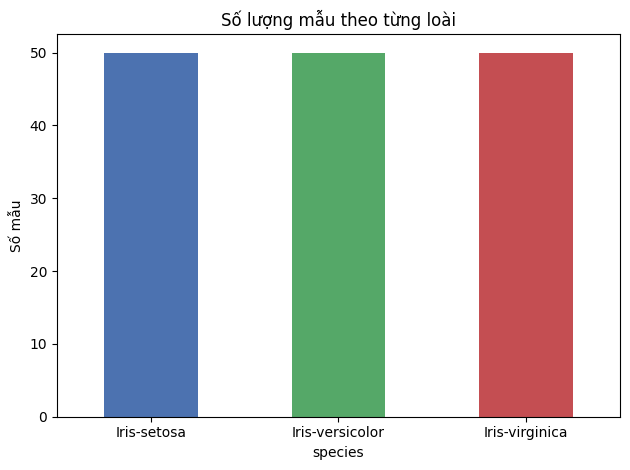

In [7]:
class_counts = data["species"].value_counts()
print(class_counts)

class_counts.plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"])
plt.title("Số lượng mẫu theo từng loài")
plt.ylabel("Số mẫu")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

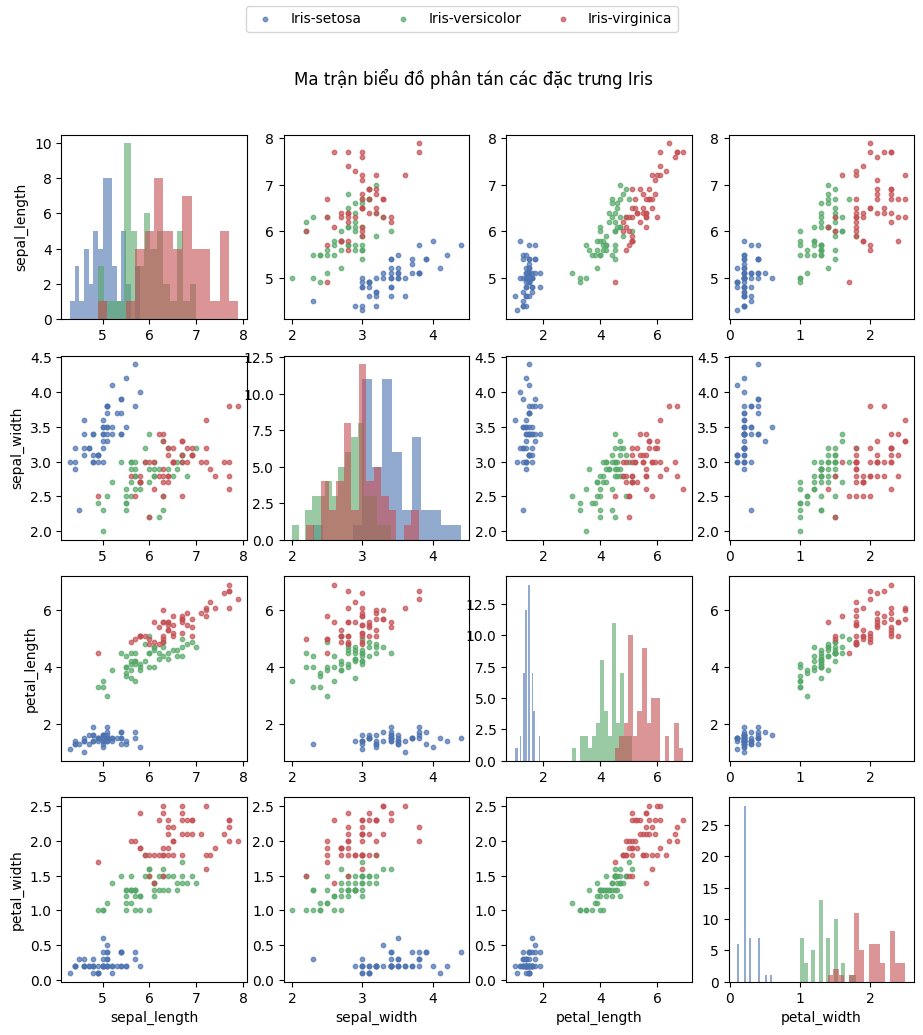

In [8]:
feature_names = list(X.columns)
species_names = data["species"].unique()
colors = {"Iris-setosa": "#4C72B0", "Iris-versicolor": "#55A868", "Iris-virginica": "#C44E52"}

fig, axes = plt.subplots(len(feature_names), len(feature_names), figsize=(11, 11))
for row, feature_y in enumerate(feature_names):
    for col, feature_x in enumerate(feature_names):
        ax = axes[row, col]
        for species in species_names:
            subset = data[data["species"] == species]
            if row == col:
                ax.hist(subset[feature_x], bins=15, alpha=0.6, color=colors[species], label=species)
            else:
                ax.scatter(
                    subset[feature_x], subset[feature_y], s=10, alpha=0.7,
                    color=colors[species], label=species,
                )
        if row == len(feature_names) - 1:
            ax.set_xlabel(feature_x)
        if col == 0:
            ax.set_ylabel(feature_y)
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3)
fig.suptitle("Ma trận biểu đồ phân tán các đặc trưng Iris", y=0.94)

plt.show()

---
## **4. Mã hoá nhãn**

Nhãn loài hoa là **chuỗi**, nhưng mạng nơ-ron cần **số**. Cách đơn giản là gán mỗi nhãn một số nguyên 0, 1, 2. Tuy nhiên điều này gây ra vấn đề: mô hình có thể "hiểu" rằng `Iris-virginica` (2) = `Iris-setosa` (0) + `Iris-versicolor` (1), điều hoàn toàn vô nghĩa.

Trong thống kê có các **cấp độ đo lường** (levels of measurement):

- **Định danh:** phân loại, không có thứ tự.
- **Thứ bậc:** có thứ tự.
- **Khoảng:** hiệu có ý nghĩa, mốc 0 tuỳ ý.
- **Tỉ lệ:** mốc 0 thực, phép chia có ý nghĩa.

Nhãn loài là dữ liệu định danh nên không thể dùng số nguyên làm thứ bậc. One-hot encoding biểu diễn mỗi loài bằng một vector có một phần tử bằng 1:

| Loài | 0 | 1 | 2 |
|---|---|---|---|
| Iris-setosa | 1 | 0 | 0 |
| Iris-versicolor | 0 | 1 | 0 |
| Iris-virginica | 0 | 0 | 1 |

`LabelEncoder` đổi tên loài thành số; `OneHotEncoder` tạo vector dùng để huấn luyện.

### **4.1. LabelEncoder**

In [9]:
# Giữ nhãn số để đối chiếu thứ tự lớp khi đánh giá.
label_encoder = LabelEncoder().fit(y.values.ravel())
y_int = label_encoder.transform(y.values.ravel())

print("Các lớp:", label_encoder.classes_)
print("Ánh xạ:", {name: int(idx) for idx, name in enumerate(label_encoder.classes_)})
print("Một vài nhãn số nguyên:", y_int[:3], "...", y_int[-3:])

Các lớp: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Ánh xạ: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Một vài nhãn số nguyên: [0 0 0] ... [2 2 2]


### **4.2. OneHotEncoder**

In [10]:
# Mã hoá mỗi loài thành vector one-hot.
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(y)
print(ohe.categories_)

y = ohe.transform(y)
# Chỉ in vài hàng để output gọn.
with np.printoptions(threshold=10, edgeitems=3):
    print(y)

[array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)]
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 ...
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]]


In [11]:
# Đảm bảo thứ tự lớp của hai encoder khớp nhau.
assert list(ohe.categories_[0]) == list(label_encoder.classes_)
assert np.array_equal(np.argmax(y, axis=1), y_int)
print("Thứ tự lớp của OneHotEncoder và LabelEncoder khớp nhau.")

Thứ tự lớp của OneHotEncoder và LabelEncoder khớp nhau.


---
## **5. Xây dựng mô hình MLP**

Mô hình nhận 4 đặc trưng, có một lớp ẩn 8 nút và xuất 3 giá trị tương ứng với 3 loài:

```
4 đầu vào  ──►  8 nút ẩn (ReLU)  ──►  3 đầu ra
```

Cấu trúc: 4–8–3.

### **5.1. Softmax**

Ở lớp đầu ra của bài toán đa lớp, ta dùng **softmax**:

$$\sigma(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{3} e^{z_j}}$$

Softmax biến logits thành xác suất có tổng bằng 1. Với `CrossEntropyLoss`, PyTorch tự xử lý softmax nên lớp cuối chỉ cần trả logits.

In [12]:
class Multiclass(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(4, 8)
        self.act = nn.ReLU()
        self.output = nn.Linear(8, 3)

    def forward(self, x):
        x = self.act(self.hidden(x))
        x = self.output(x)
        return x


model = Multiclass()
print(model)
print("Tổng số tham số:", sum(p.numel() for p in model.parameters()))

Multiclass(
  (hidden): Linear(in_features=4, out_features=8, bias=True)
  (act): ReLU()
  (output): Linear(in_features=8, out_features=3, bias=True)
)
Tổng số tham số: 67


Mô hình trả về logits cho mỗi lớp. Ô dưới đây minh hoạ softmax trước khi mô hình được huấn luyện.

In [13]:
with torch.no_grad():
    sample_logits = model(torch.tensor(X.values[:3], dtype=torch.float32))
    sample_probs = torch.softmax(sample_logits, dim=1)
print("Logit:\n", sample_logits)
print("Softmax:\n", sample_probs)
print("Tổng mỗi hàng:", sample_probs.sum(dim=1))

Logit:
 tensor([[ 1.9520, -0.8253,  0.4570],
        [ 1.8819, -0.8640,  0.4761],
        [ 1.8185, -0.7669,  0.4418]])
Softmax:
 tensor([[0.7773, 0.0484, 0.1743],
        [0.7637, 0.0490, 0.1872],
        [0.7531, 0.0568, 0.1901]])
Tổng mỗi hàng: tensor([1.0000, 1.0000, 1.0000])


### **5.2. Hàm mất mát: cross-entropy**

Với phân loại đa lớp, ta thường dùng **categorical cross-entropy**:

$$H(p, q) = -\sum_{x} p(x) \log q(x)$$

Với nhãn one-hot, loss phạt dự đoán có xác suất thấp cho lớp đúng.

`nn.CrossEntropyLoss` nhận logits trực tiếp. Mô hình dùng Adam với learning rate 0.001.

In [14]:
loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

sample_targets = torch.tensor(y[:3], dtype=torch.float32)
manual_ce = -(sample_targets * torch.log(sample_probs)).sum(dim=1).mean()
print("CrossEntropyLoss :", float(loss_fn(sample_logits, sample_targets)))
print("Tính theo công thức:", float(manual_ce))

CrossEntropyLoss : 0.26830682158470154
Tính theo công thức: 0.2683068513870239


### **5.3. Chuyển dữ liệu và huấn luyện**

Mỗi batch gồm ba bước:

1. Tính đầu ra và loss.
2. Lan truyền gradient ngược.
3. Cập nhật trọng số.

Ở bước này mô hình học trên toàn bộ dữ liệu để minh hoạ vòng lặp cơ bản.

Thanh tiến trình chỉ hiện mỗi 50 epoch để tránh quá nhiều đầu ra.

In [15]:
X = torch.tensor(X.values, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)
print("X:", X.shape, X.dtype, "| y:", y.shape, y.dtype)

X: torch.Size([150, 4]) torch.float32 | y: torch.Size([150, 3]) torch.float32


In [16]:
n_epochs = 200
batch_size = 5
batches_per_epoch = len(X) // batch_size
PROGRESS_EVERY = 50

for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0,
                     disable=(epoch % PROGRESS_EVERY != 0)) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
            start = i * batch_size
            X_batch = X[start:start + batch_size]
            y_batch = y[start:start + batch_size]
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

with torch.no_grad():
    full_pred = model(X)
    full_acc = (torch.argmax(full_pred, 1) == torch.argmax(y, 1)).float().mean()
print(
    f"Loss cuối (toàn bộ dữ liệu) = {float(loss_fn(full_pred, y)):.4f}, "
    f"Accuracy = {float(full_acc) * 100:.1f}%"
)

Epoch 150: 100%|██████████| 30/30 [00:00<00:00, 257.64batch/s]


Loss cuối (toàn bộ dữ liệu) = 0.1234, Accuracy = 97.3%


---
## **6. Đánh giá mô hình**

Tách dữ liệu thành tập train và test để kiểm tra khả năng dự đoán trên các mẫu mô hình chưa thấy.

Kết quả test kém hơn train có thể là dấu hiệu overfitting.

### **6.1. Chia train/test**

Dùng 70% dữ liệu để huấn luyện, 30% để kiểm tra. `random_state` giúp tái lập kết quả.

In [17]:
# Dữ liệu được sắp theo loài nên cần xáo trộn trước khi chia.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, shuffle=True, random_state=RANDOM_SEED
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Số mẫu mỗi lớp trong train:", y_train.sum(dim=0).tolist())
print("Số mẫu mỗi lớp trong test: ", y_test.sum(dim=0).tolist())

Train: torch.Size([105, 4]) | Test: torch.Size([45, 4])
Số mẫu mỗi lớp trong train: [31.0, 37.0, 37.0]
Số mẫu mỗi lớp trong test:  [19.0, 13.0, 13.0]


### **6.2. Chuẩn hoá đặc trưng**

Dùng `StandardScaler` để đưa đặc trưng về trung bình 0 và độ lệch chuẩn 1.

Chỉ `fit` scaler trên tập train rồi dùng scaler đó cho test, tránh rò rỉ dữ liệu.

In [18]:
# Chỉ fit scaler trên train để tránh rò rỉ dữ liệu.
scaler = StandardScaler().fit(X_train.numpy())

X_train = torch.tensor(scaler.transform(X_train.numpy()), dtype=torch.float32)
X_test = torch.tensor(scaler.transform(X_test.numpy()), dtype=torch.float32)

print("Trung bình train sau chuẩn hoá:", X_train.mean(dim=0).numpy().round(3))
print("Độ lệch chuẩn train sau chuẩn hoá:", X_train.std(dim=0, unbiased=False).numpy().round(3))
print(
    "Trung bình test sau chuẩn hoá:", X_test.mean(dim=0).numpy().round(3)
)

Trung bình train sau chuẩn hoá: [ 0.  0.  0. -0.]
Độ lệch chuẩn train sau chuẩn hoá: [1. 1. 1. 1.]
Trung bình test sau chuẩn hoá: [ 0.002  0.397 -0.22  -0.177]


### **6.3. Huấn luyện và đánh giá**

In [19]:
# Khởi tạo lại vì mô hình trước đã thấy cả tập test.
torch.manual_seed(RANDOM_SEED)
model = Multiclass()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

n_epochs = 200
batch_size = 5
batches_per_epoch = len(X_train) // batch_size
PRINT_EVERY = 20

for epoch in range(n_epochs):
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0,
                     disable=(epoch % PROGRESS_EVERY != 0)) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
            start = i * batch_size
            X_batch = X_train[start:start + batch_size]
            y_batch = y_train[start:start + batch_size]
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    y_pred = model(X_test)
    ce = loss_fn(y_pred, y_test)
    acc = (torch.argmax(y_pred, 1) == torch.argmax(y_test, 1)).float().mean()
    if epoch % PRINT_EVERY == 0 or epoch == n_epochs - 1:
        print(
            f"Epoch {epoch} validation: Cross-entropy={float(ce):.4f}, "
            f"Accuracy={float(acc) * 100:.1f}%"
        )

Epoch 0: 100%|██████████| 21/21 [00:00<00:00, 256.75batch/s]

Epoch 0 validation: Cross-entropy=1.1118, Accuracy=8.9%


Epoch 20 validation: Cross-entropy=0.3694, Accuracy=86.7%
Epoch 40 validation: Cross-entropy=0.2115, Accuracy=91.1%


Epoch 50: 100%|██████████| 21/21 [00:00<00:00, 286.43batch/s]


Epoch 60 validation: Cross-entropy=0.1203, Accuracy=100.0%
Epoch 80 validation: Cross-entropy=0.0774, Accuracy=100.0%


Epoch 100: 100%|██████████| 21/21 [00:00<00:00, 293.80batch/s]


Epoch 100 validation: Cross-entropy=0.0577, Accuracy=100.0%
Epoch 120 validation: Cross-entropy=0.0474, Accuracy=100.0%
Epoch 140 validation: Cross-entropy=0.0409, Accuracy=100.0%


Epoch 150: 100%|██████████| 21/21 [00:00<00:00, 245.49batch/s]


Epoch 160 validation: Cross-entropy=0.0365, Accuracy=100.0%
Epoch 180 validation: Cross-entropy=0.0332, Accuracy=100.0%
Epoch 199 validation: Cross-entropy=0.0306, Accuracy=100.0%


---
### **6.4. Lưu mô hình tốt nhất**

Lưu loss và accuracy theo từng epoch, đồng thời giữ lại trọng số có accuracy test cao nhất.

Một vài lưu ý khi train và đánh giá:

Các điểm thực hành tốt được sách nêu:

- Dùng `model.train()` khi huấn luyện và `model.eval()` khi đánh giá.
- Dùng `copy.deepcopy(model.state_dict())` để lưu bản trọng số độc lập.

Khởi tạo lại mô hình để bắt đầu quá trình đánh giá từ đầu.

In [20]:
torch.manual_seed(RANDOM_SEED)
model = Multiclass()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

n_epochs = 200
batch_size = 5
batches_per_epoch = len(X_train) // batch_size

best_acc = -np.inf
best_weights = None
best_epoch = -1
train_loss_hist = []
train_acc_hist = []
test_loss_hist = []
test_acc_hist = []

for epoch in range(n_epochs):
    epoch_loss = []
    epoch_acc = []
    model.train()
    with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0,
                     disable=(epoch % PROGRESS_EVERY != 0)) as bar:
        bar.set_description(f"Epoch {epoch}")
        for i in bar:
            start = i * batch_size
            X_batch = X_train[start:start + batch_size]
            y_batch = y_train[start:start + batch_size]
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            acc = (torch.argmax(y_pred, 1) == torch.argmax(y_batch, 1)).float().mean()
            epoch_loss.append(float(loss))
            epoch_acc.append(float(acc))
            bar.set_postfix(loss=float(loss), acc=float(acc))
    model.eval()
    with torch.no_grad():
        y_pred = model(X_test)
        ce = loss_fn(y_pred, y_test)
        acc = (torch.argmax(y_pred, 1) == torch.argmax(y_test, 1)).float().mean()
    ce = float(ce)
    acc = float(acc)
    train_loss_hist.append(np.mean(epoch_loss))
    train_acc_hist.append(np.mean(epoch_acc))
    test_loss_hist.append(ce)
    test_acc_hist.append(acc)
    if acc > best_acc:
        best_acc = acc
        best_epoch = epoch
        best_weights = copy.deepcopy(model.state_dict())
    if epoch % PRINT_EVERY == 0 or epoch == n_epochs - 1:
        print(f"Epoch {epoch} validation: Cross-entropy={ce:.2f}, Accuracy={acc * 100:.1f}%")

model.load_state_dict(best_weights)
print(
    f"\nĐã khôi phục mô hình tốt nhất tại epoch {best_epoch} "
    f"với accuracy test = {best_acc * 100:.1f}%"
)

Epoch 0: 100%|██████████| 21/21 [00:00<00:00, 105.27batch/s, acc=0, loss=1.1]   


Epoch 0 validation: Cross-entropy=1.11, Accuracy=8.9%
Epoch 20 validation: Cross-entropy=0.37, Accuracy=86.7%
Epoch 40 validation: Cross-entropy=0.21, Accuracy=91.1%


Epoch 50: 100%|██████████| 21/21 [00:00<00:00, 182.62batch/s, acc=0.8, loss=0.274]


Epoch 60 validation: Cross-entropy=0.12, Accuracy=100.0%
Epoch 80 validation: Cross-entropy=0.08, Accuracy=100.0%


Epoch 100: 100%|██████████| 21/21 [00:00<00:00, 161.07batch/s, acc=1, loss=0.0817] 


Epoch 100 validation: Cross-entropy=0.06, Accuracy=100.0%
Epoch 120 validation: Cross-entropy=0.05, Accuracy=100.0%
Epoch 140 validation: Cross-entropy=0.04, Accuracy=100.0%


Epoch 150: 100%|██████████| 21/21 [00:00<00:00, 178.05batch/s, acc=1, loss=0.0492] 


Epoch 160 validation: Cross-entropy=0.04, Accuracy=100.0%
Epoch 180 validation: Cross-entropy=0.03, Accuracy=100.0%
Epoch 199 validation: Cross-entropy=0.03, Accuracy=100.0%

Đã khôi phục mô hình tốt nhất tại epoch 55 với accuracy test = 100.0%


---
### **6.5. Đồ thị loss và accuracy**

So sánh loss và accuracy của train/test để theo dõi quá trình học và phát hiện overfitting.

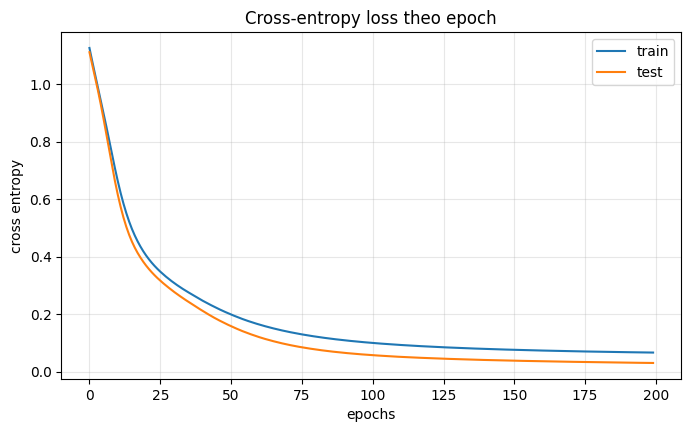

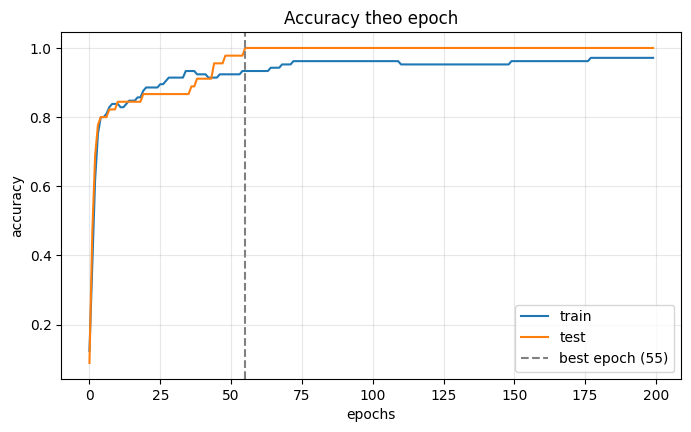

In [21]:
plt.figure(figsize=(8, 4.5))
plt.plot(train_loss_hist, label="train")
plt.plot(test_loss_hist, label="test")
plt.xlabel("epochs")
plt.ylabel("cross entropy")
plt.title("Cross-entropy loss theo epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4.5))
plt.plot(train_acc_hist, label="train")
plt.plot(test_acc_hist, label="test")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("Accuracy theo epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## **7. Đánh giá mô hình tốt nhất**

In [22]:
model.eval()
with torch.no_grad():
    test_logits = model(X_test)
    test_ce = float(loss_fn(test_logits, y_test))
y_test_pred = torch.argmax(test_logits, 1).numpy()
y_test_true = torch.argmax(y_test, 1).numpy()
test_accuracy = (y_test_pred == y_test_true).mean()

with torch.no_grad():
    train_accuracy = (torch.argmax(model(X_train), 1) == torch.argmax(y_train, 1)).float().mean().item()

print(f"Accuracy trên tập train : {train_accuracy * 100:.2f}%")
print(f"Accuracy trên tập test  : {test_accuracy * 100:.2f}%")
print(f"Cross-entropy trên test : {test_ce:.4f}")
print("Mục tiêu theo sách: 95% - 97%")

Accuracy trên tập train : 93.33%
Accuracy trên tập test  : 100.00%
Cross-entropy trên test : 0.1376
Mục tiêu theo sách: 95% - 97%


> Tập test chỉ có 45 mẫu nên mỗi dự đoán sai làm accuracy thay đổi khoảng 2,2%. Kết quả cũng có thể khác theo cách chia dữ liệu. Accuracy test cao hơn train không bất thường với tập nhỏ; nên xem thêm loss và ma trận nhầm lẫn.

[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


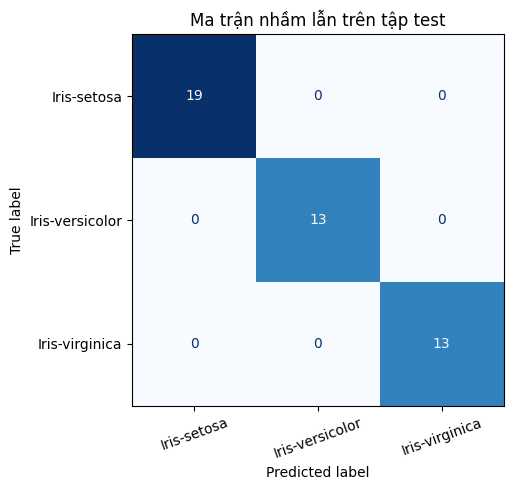

In [23]:
class_names = label_encoder.classes_
cm = confusion_matrix(y_test_true, y_test_pred, labels=range(len(class_names)))
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Ma trận nhầm lẫn trên tập test")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [24]:
print(classification_report(y_test_true, y_test_pred, target_names=class_names, digits=4))

                 precision    recall  f1-score   support

    Iris-setosa     1.0000    1.0000    1.0000        19
Iris-versicolor     1.0000    1.0000    1.0000        13
 Iris-virginica     1.0000    1.0000    1.0000        13

       accuracy                         1.0000        45
      macro avg     1.0000    1.0000    1.0000        45
   weighted avg     1.0000    1.0000    1.0000        45



In [25]:
test_probs = torch.softmax(test_logits, dim=1).numpy()
preview = pd.DataFrame(test_probs[:8].round(4), columns=[f"P({name})" for name in class_names])
preview["predicted"] = label_encoder.inverse_transform(y_test_pred[:8])
preview["actual"] = label_encoder.inverse_transform(y_test_true[:8])
preview

,P(Iris-setosa),P(Iris-versicolor),P(Iris-virginica),predicted,actual
0,0.0191,0.8415,0.1394,Iris-versicolor,Iris-versicolor
1,0.9948,0.0038,0.0015,Iris-setosa,Iris-setosa
2,0.0000,0.0069,0.9930,Iris-virginica,Iris-virginica
3,0.0242,0.6502,0.3256,Iris-versicolor,Iris-versicolor
4,0.0101,0.6576,0.3323,Iris-versicolor,Iris-versicolor
5,0.9879,0.0093,0.0027,Iris-setosa,Iris-setosa
6,0.1011,0.7777,0.1212,Iris-versicolor,Iris-versicolor
7,0.0013,0.0324,0.9663,Iris-virginica,Iris-virginica


### **7.1. Dự đoán mẫu mới**

Dùng lại scaler đã fit trên train trước khi đưa dữ liệu mới vào mô hình.

In [26]:
# Dùng lại scaler đã fit trên train.
new_flowers = pd.DataFrame(
    [[5.0, 3.4, 1.5, 0.2], [6.0, 2.8, 4.5, 1.4], [6.9, 3.1, 5.8, 2.2]],
    columns=feature_names,
)
new_tensor = torch.tensor(scaler.transform(new_flowers.values), dtype=torch.float32)
with torch.no_grad():
    new_probs = torch.softmax(model(new_tensor), dim=1).numpy()
new_flowers["predicted_species"] = label_encoder.inverse_transform(new_probs.argmax(axis=1))
new_flowers["confidence"] = new_probs.max(axis=1).round(4)
new_flowers

,sepal_length,sepal_width,petal_length,petal_width,predicted_species,confidence
0,5.0,3.4,1.5,0.2,Iris-setosa,0.9944
1,6.0,2.8,4.5,1.4,Iris-versicolor,0.7438
2,6.9,3.1,5.8,2.2,Iris-virginica,0.9753


---
## **8. Ví dụ hoàn chỉnh**

Ô này gom toàn bộ quy trình vào một hàm để chạy lại từ đầu. Cần có `iris.csv` và lớp `Multiclass`.

Epoch 0 validation: Cross-entropy=1.11, Accuracy=8.9%
Epoch 50 validation: Cross-entropy=0.16, Accuracy=97.8%
Epoch 100 validation: Cross-entropy=0.06, Accuracy=100.0%
Epoch 150 validation: Cross-entropy=0.04, Accuracy=100.0%
Epoch 199 validation: Cross-entropy=0.03, Accuracy=100.0%


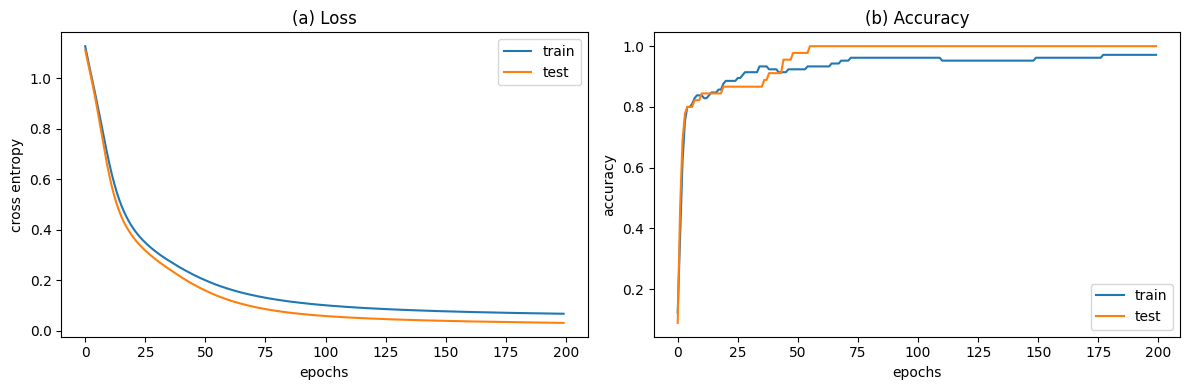

Accuracy test tốt nhất của ví dụ hoàn chỉnh: 100.0%


In [28]:
def run_complete_example(csv_path="data/iris.csv", n_epochs=200, batch_size=5, seed=42, print_every=50):
    torch.manual_seed(seed)

    data = pd.read_csv(csv_path, header=0)
    X = data.iloc[:, 0:4]
    y = data.iloc[:, 4:]
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(y)
    y = ohe.transform(y)

    X = torch.tensor(X.values, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=0.7, shuffle=True, random_state=seed
    )

    scaler = StandardScaler().fit(X_train.numpy())
    X_train = torch.tensor(scaler.transform(X_train.numpy()), dtype=torch.float32)
    X_test = torch.tensor(scaler.transform(X_test.numpy()), dtype=torch.float32)

    model = Multiclass()
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    batches_per_epoch = len(X_train) // batch_size
    best_acc = -np.inf
    best_weights = None
    train_loss_hist, train_acc_hist, test_loss_hist, test_acc_hist = [], [], [], []

    for epoch in range(n_epochs):
        epoch_loss, epoch_acc = [], []
        model.train()
        with tqdm.trange(batches_per_epoch, unit="batch", mininterval=0, disable=True) as bar:
            bar.set_description(f"Epoch {epoch}")
            for i in bar:
                start = i * batch_size
                X_batch = X_train[start:start + batch_size]
                y_batch = y_train[start:start + batch_size]
                y_pred = model(X_batch)
                loss = loss_fn(y_pred, y_batch)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                acc = (torch.argmax(y_pred, 1) == torch.argmax(y_batch, 1)).float().mean()
                epoch_loss.append(float(loss))
                epoch_acc.append(float(acc))
                bar.set_postfix(loss=float(loss), acc=float(acc))
        model.eval()
        with torch.no_grad():
            y_pred = model(X_test)
            ce = float(loss_fn(y_pred, y_test))
            acc = float((torch.argmax(y_pred, 1) == torch.argmax(y_test, 1)).float().mean())
        train_loss_hist.append(np.mean(epoch_loss))
        train_acc_hist.append(np.mean(epoch_acc))
        test_loss_hist.append(ce)
        test_acc_hist.append(acc)
        if acc > best_acc:
            best_acc = acc
            best_weights = copy.deepcopy(model.state_dict())
        if epoch % print_every == 0 or epoch == n_epochs - 1:
            print(f"Epoch {epoch} validation: Cross-entropy={ce:.2f}, Accuracy={acc * 100:.1f}%")

    model.load_state_dict(best_weights)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    ax_loss.plot(train_loss_hist, label="train")
    ax_loss.plot(test_loss_hist, label="test")
    ax_loss.set_xlabel("epochs")
    ax_loss.set_ylabel("cross entropy")
    ax_loss.set_title("(a) Loss")
    ax_loss.legend()
    ax_acc.plot(train_acc_hist, label="train")
    ax_acc.plot(test_acc_hist, label="test")
    ax_acc.set_xlabel("epochs")
    ax_acc.set_ylabel("accuracy")
    ax_acc.set_title("(b) Accuracy")
    ax_acc.legend()
    plt.tight_layout()
    plt.show()

    return model, best_acc


complete_model, complete_best_acc = run_complete_example()
print(f"Accuracy test tốt nhất của ví dụ hoàn chỉnh: {complete_best_acc * 100:.1f}%")

---
## **9. Tài liệu tham khảo**

- [Iris Data Set – UCI](https://archive.ics.uci.edu/ml/datasets/Iris)
- [`torch.nn.Softmax`](https://pytorch.org/docs/stable/generated/torch.nn.Softmax.html) và [`torch.nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [`OneHotEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

---
## **10. Tổng kết**

Chạy thử với Iris cho thấy mô hình phân loại khá tốt, nhưng kết quả còn phụ thuộc vào cách chia tập vì test chỉ có 45 mẫu. Mình cũng thấy bước chuẩn bị dữ liệu rất quan trọng: mã hoá nhãn one-hot và chỉ fit scaler trên train. Xem thêm loss và ma trận nhầm lẫn giúp hiểu mô hình sai ở đâu, thay vì chỉ nhìn accuracy.

Tập test của Iris khá nhỏ nên accuracy có thể thay đổi theo cách chia dữ liệu. Xem thêm loss và ma trận nhầm lẫn sẽ giúp hiểu kết quả rõ hơn.

# <center>**HẾT**<center>